# Regression tools homework

Compare single-feature linear regression for BMI and average blood pressure using the built-in diabetes data, then explore all nine exercise/physiology pairs in Linnerud. This notebook runs from its own directory without external files or downloads.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_linnerud
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

%matplotlib inline

## Diabetes: a fair feature comparison

The target is a quantitative measure of diabetes progression one year after baseline. BMI (`bmi`) and average blood pressure (`bp`) are scaled features. Both models use the same 67% training / 33% test rows and `random_state=42`, so differences in test R² and RMSE reflect the chosen feature on this split. R² compares against a constant prediction; RMSE is in target units, with lower values indicating smaller prediction errors.

In [2]:
diabetes = load_diabetes()
assert diabetes.data.shape == (442, 10)
assert diabetes.target.shape == (442,)
assert np.isfinite(diabetes.data).all() and np.isfinite(diabetes.target).all()

train_rows, test_rows = train_test_split(
    np.arange(442), test_size=0.33, random_state=42
)
assert train_rows.shape == (296,) and test_rows.shape == (146,)
assert not np.intersect1d(train_rows, test_rows).size
print(f"Diabetes: {len(train_rows)} training rows; {len(test_rows)} test rows.")

Diabetes: 296 training rows; 146 test rows.


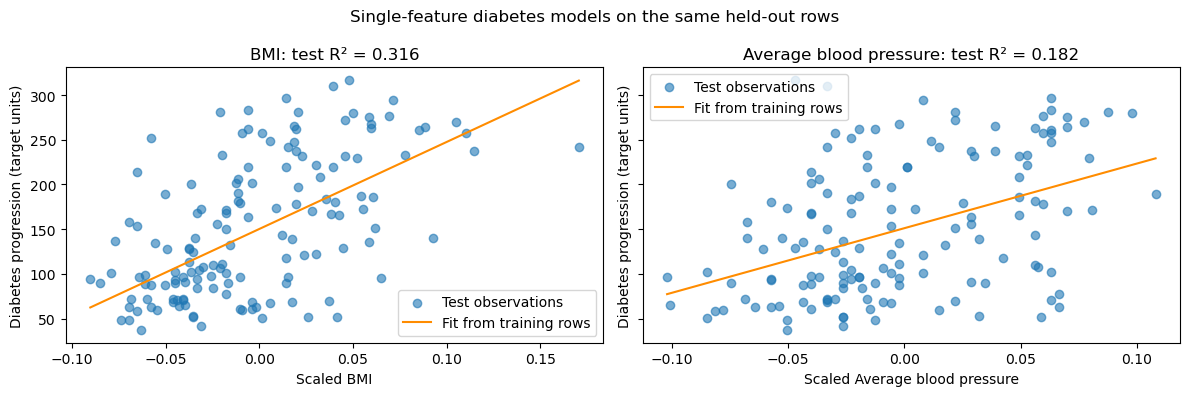

Feature  Test R²  Test RMSE
    bmi   0.3164    62.7221
     bp   0.1817    68.6275


In [3]:
diabetes_results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, feature, label in zip(axes, ("bmi", "bp"), ("BMI", "Average blood pressure")):
    feature_index = diabetes.feature_names.index(feature)
    X = diabetes.data[:, [feature_index]]
    model = LinearRegression().fit(X[train_rows], diabetes.target[train_rows])
    predictions = model.predict(X[test_rows])
    assert predictions.shape == (146,) and np.isfinite(predictions).all()
    score = r2_score(diabetes.target[test_rows], predictions)
    rmse = np.sqrt(mean_squared_error(diabetes.target[test_rows], predictions))
    assert np.isfinite([score, rmse]).all()
    diabetes_results.append({"Feature": feature, "Test R²": score, "Test RMSE": rmse})
    order = np.argsort(X[test_rows, 0])
    ax.scatter(X[test_rows, 0], diabetes.target[test_rows], alpha=0.6, label="Test observations")
    ax.plot(X[test_rows, 0][order], predictions[order], color="darkorange", label="Fit from training rows")
    ax.set(xlabel=f"Scaled {label}", ylabel="Diabetes progression (target units)", title=f"{label}: test R² = {score:.3f}")
    ax.legend()
fig.suptitle("Single-feature diabetes models on the same held-out rows")
fig.tight_layout()
plt.show()

comparison = pd.DataFrame(diabetes_results)
assert comparison.shape == (2, 3)
print(comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

A feature with higher test R² and lower test RMSE predicts this held-out target better on this split. A single feature leaves substantial variation unexplained. This split is an educational comparison, not clinical validation; associations do not establish causes or treatment effects.

## Linnerud: all nine descriptive relationships

Linnerud contains only 20 rows, collected from middle-aged men in a fitness club. Each exercise feature (Chins, Situps, Jumps) is paired with each physiological target (Weight, Waist, Pulse). Fit each line to all 20 observations to describe the sample; the reported R²/RMSE are in-sample summaries, not estimates of performance on new people. This small sample makes the analysis exploratory and non-causal.

In [4]:
linnerud = load_linnerud()
assert linnerud.data.shape == (20, 3)
assert linnerud.target.shape == (20, 3)
assert np.isfinite(linnerud.data).all() and np.isfinite(linnerud.target).all()
print("Linnerud: 20 rows; exercises:", linnerud.feature_names, "; physiology:", linnerud.target_names)

Linnerud: 20 rows; exercises: ['Chins', 'Situps', 'Jumps'] ; physiology: ['Weight', 'Waist', 'Pulse']


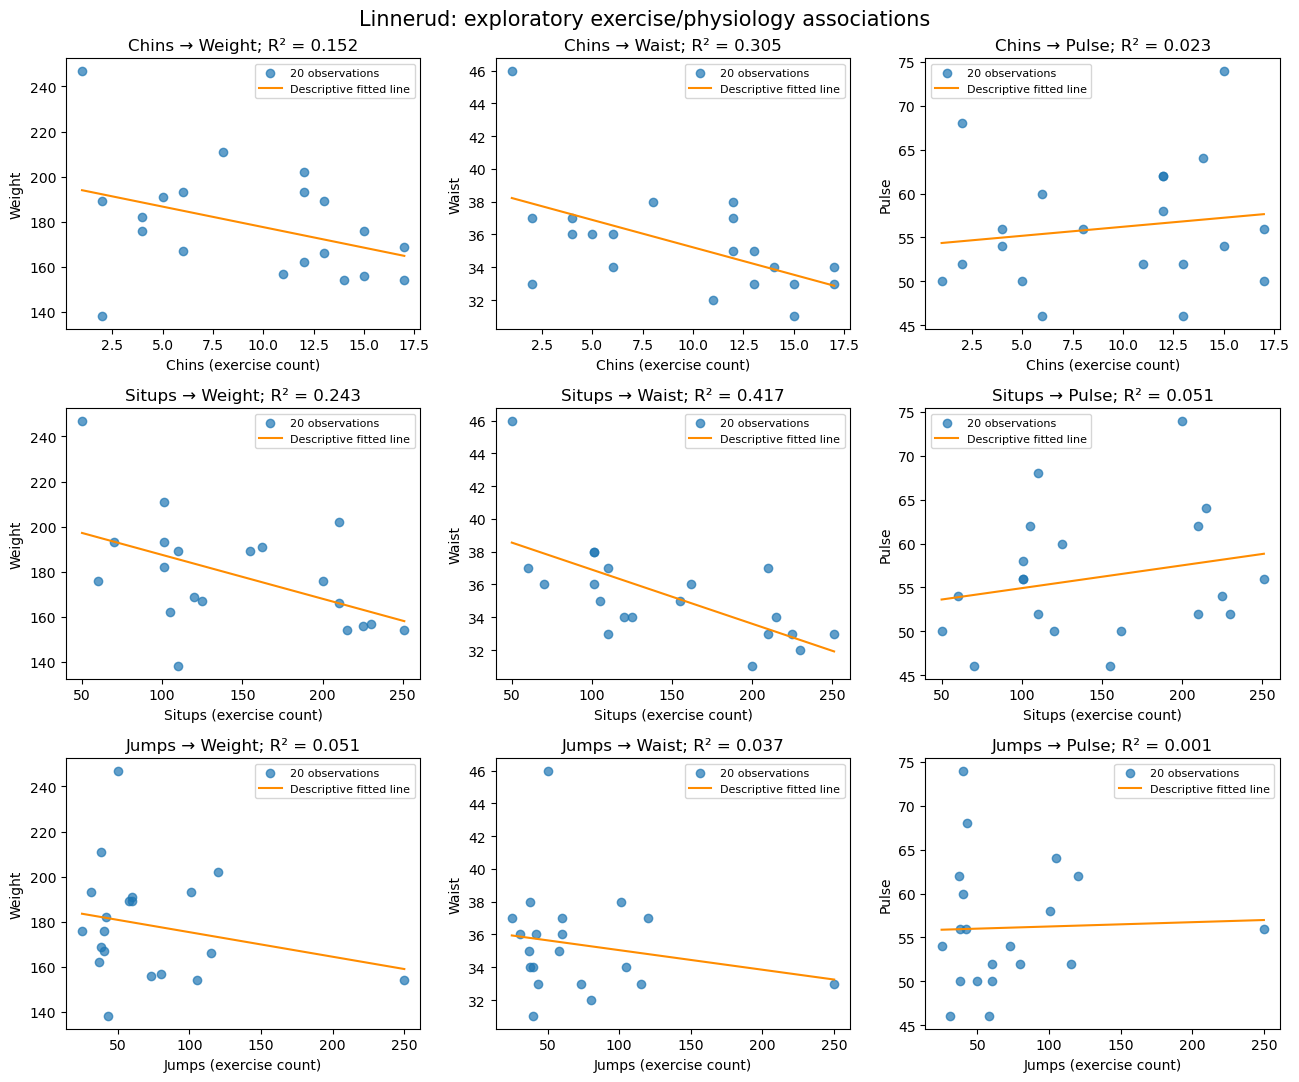

Exercise Target   Slope  Correlation  In-sample R²  In-sample RMSE
   Chins Weight -1.8201      -0.3897        0.1519         22.1628
   Chins  Waist -0.3345      -0.5522        0.3050          2.6019
   Chins  Pulse  0.2055       0.1506        0.0227          6.9476
  Situps Weight -0.1946      -0.4931        0.2431         20.9364
  Situps  Waist -0.0330      -0.6456        0.4168          2.3834
  Situps  Pulse  0.0259       0.2250        0.0506          6.8475
   Jumps Weight -0.1090      -0.2263        0.0512         23.4410
   Jumps  Waist -0.0120      -0.1915        0.0367          3.0631
   Jumps  Pulse  0.0049       0.0349        0.0012          7.0235


In [5]:
linnerud_results = []
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for exercise_index, exercise in enumerate(linnerud.feature_names):
    X = linnerud.data[:, [exercise_index]]
    for target_index, target in enumerate(linnerud.target_names):
        y = linnerud.target[:, target_index]
        model = LinearRegression().fit(X, y)
        predictions = model.predict(X)
        score = r2_score(y, predictions)
        rmse = np.sqrt(mean_squared_error(y, predictions))
        correlation = np.corrcoef(X[:, 0], y)[0, 1]
        slope = model.coef_[0]
        assert predictions.shape == (20,)
        assert np.isfinite(predictions).all()
        assert np.isfinite([score, rmse, correlation, slope]).all()
        linnerud_results.append({"Exercise": exercise, "Target": target, "Slope": slope, "Correlation": correlation, "In-sample R²": score, "In-sample RMSE": rmse})
        ax = axes[exercise_index, target_index]
        grid = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
        ax.scatter(X[:, 0], y, alpha=0.7, label="20 observations")
        ax.plot(grid[:, 0], model.predict(grid), color="darkorange", label="Descriptive fitted line")
        ax.set(xlabel=f"{exercise} (exercise count)", ylabel=target, title=f"{exercise} → {target}; R² = {score:.3f}")
        ax.legend(fontsize=8)
fig.suptitle("Linnerud: exploratory exercise/physiology associations", fontsize=15)
fig.tight_layout()
plt.show()

relationships = pd.DataFrame(linnerud_results)
assert relationships.shape == (9, 6)
print(relationships.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

The Situps → Waist panel directly answers the assignment: situps are the one-column input, waist is the response, and the fitted line describes their association. Repeat the same procedure for the other eight pairs. The 20-row small sample, observational design, and limited population do not support causal conclusions or broad generalization.